# Homework 5A: “Done—Looks Great!”

**Due Thursday, November 12, 2026, at 11:59 p.m. Central.**

Your manager forwards a notebook from a former colleague with the following note:

> He was very enthusiastic about AI-assisted analysis. Checking the results... not so much. He's since moved on. Please review and finalize the work to make it presentable.
>
> I need your revised notebook by Thursday, November 12, at 11:59 p.m. Central. Plan to spend no more than 3 hours working on this assignment, including reviewing relevant course material, implementing and checking the analysis, and writing your responses. You may continue if needed, but stop after 5 hours of assignment work. Separate study of general Python fundamentals does not count toward this limit; debugging this notebook does. You are not expected to reach the time limit. In your responses to my comments, explain what you finished and checked. For anything unfinished, show your attempt, identify the sticking point, and say what you would try next.

The notebook contains useful work, questionable choices, and unfinished analysis. Your job is to take responsibility for its **validity** (does it answer the question appropriately?), **veracity** (does the code do what it claims?), and **completeness**.

## Your Assignment

**Review, correct, and complete the inherited notebook to produce a defensible analysis of Australian quarterly cement production.** Explain temporal patterns, investigate recent changes in activity, and determine whether a component-based forecast improves on time-only regression.

Use the provided 1990–2009 data. Take the end of **2007 Q4** as the information boundary for the briefing: use history through that date for component estimates, adjustment comparisons, dependence analysis, and model fitting. Evaluate forecasts on the **eight quarters of 2008–2009**.

Adjust the inherited work as appropriate. Add code and Markdown cells where needed. You do not need to reproduce every element from the lectures, implement additional forecast models (except as directed), or write a separate report.

This individual assignment is worth **10 points**. Partial credit is available for sound analysis, correct diagnoses, and meaningful progress, even when a section is unfinished. Make your work and reasoning visible.

You may use lectures, documentation, and AI assistance to understand, implement, and check your work. Your explanations must be your own, and you must be able to explain or revise the code and reasoning. Record material assistance and how you verified it. The original analyst's problem was submitting unchecked work; using assistance does not transfer your responsibility for the result.

References: [11a: decomposition](https://github.com/olearydj/INSY7130/blob/main/lectures/11a-time-series-and-decomposition/11a-time-series-and-decomposition.ipynb), [11b: dependence and differencing](https://github.com/olearydj/INSY7130/blob/main/lectures/11b-autocorrelation-and-stationarity/11b-autocorrelation-and-stationarity.ipynb), and [12a: forecasting](https://github.com/olearydj/INSY7130/blob/main/lectures/12a-basic-forecasting/12a-basic-forecasting.ipynb).

## Reliable Setup and Utilities

The briefing scenario is fictional, but the data are real, from the Australian Bureau of Statistics through the [FPP data collection](https://otexts.com/fpppy/data/aus_production.csv). The extract retains original measurements for 1990–2009 without imputation or seasonal adjustment. Each row is a national quarterly total of Australian Portland cement production, measured in **thousands of tonnes**. Quarter-start dates label whole quarters.

Data attribution and reuse terms: [Cement Production Data](https://github.com/olearydj/INSY7130/blob/main/homework/hw5a/data/README.md).

The supplied data-loading code is correct and is outside the scope of your audit.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LinearRegression
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.seasonal import seasonal_decompose

paths = [Path("cement-production.csv"), Path("data/cement-production.csv"),
         Path("content/homework/hw5a/data/cement-production.csv")]
data_url = (
    "https://raw.githubusercontent.com/olearydj/INSY7130/main/"
    "homework/hw5a/data/cement-production.csv"
)
data_source = next((p for p in paths if p.is_file()), data_url)
frame = pd.read_csv(data_source)
frame["quarter"] = pd.to_datetime(frame["quarter"], format="%Y-%m-%d")
cement = frame.set_index("quarter")["production_thousand_tonnes"].astype(float)
assert cement.index.is_unique and cement.index.is_monotonic_increasing
assert cement.index.equals(pd.date_range("1990-01-01", "2009-10-01", freq="QS"))
assert cement.notna().all()
cement = cement.asfreq("QS")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
display(cement.head().to_frame())

,production_thousand_tonnes
quarter,
1990-01-01,1565.0
1990-04-01,1645.0
1990-07-01,1658.0
1990-10-01,1668.0
1991-01-01,1343.0


The following helper functions display supplied results or score already aligned forecasts. They are optional, correct as provided, and outside the scope of your audit. Selecting the analysis data, fitting models, and deciding which evidence is appropriate belong to the inherited analysis you will review and complete.

In [2]:
def show_components(observed, result, title):
    """Plot a fitted classical or STL result against its input series."""
    fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, layout="constrained")
    axes[0].plot(observed.index, observed, color="0.65", label="Observed")
    axes[0].plot(observed.index, result.trend, label="Trend-cycle")
    axes[0].legend()
    for ax, field in zip(axes[1:], ["seasonal", "resid"], strict=True):
        ax.plot(observed.index, getattr(result, field))
        ax.axhline(0, color="0.6", linewidth=0.8)
        ax.set_title("Seasonal" if field == "seasonal" else "Remainder")
    for ax in axes:
        ax.set_ylabel("Thousand tonnes")
    axes[0].set_title(title)
    axes[-1].set_xlabel("Year")
    plt.show()
    plt.close(fig)


def show_dependence(series, title):
    """Display a series and its sample ACF through eight quarterly lags."""
    values = series.dropna()
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
    axes[0].plot(values.index, values)
    axes[0].set(title=title, xlabel="Year", ylabel="Thousand tonnes")
    plot_acf(values, lags=8, zero=False, alpha=None, ax=axes[1])
    axes[1].set(title="Sample ACF", xlabel="Lag (quarters)", ylabel="ACF", ylim=(-1, 1))
    plt.show()
    plt.close(fig)


def score_forecasts(actual, predictions):
    """Return metrics and actual-minus-predicted errors for matching date indexes.

    actual is a Series; predictions is a DataFrame with one column per method.
    This checks alignment, not whether model fitting used permissible information.
    """
    if not actual.index.equals(predictions.index):
        raise ValueError("Actuals and predictions must have the same dates in the same order.")
    if actual.isna().any() or predictions.isna().any().any():
        raise ValueError("Every evaluated date needs an actual and each method's prediction.")
    errors = predictions.rsub(actual, axis="index")
    scores = pd.DataFrame({"MAE": errors.abs().mean(),
                           "RMSE": np.sqrt(errors.pow(2).mean()),
                           "Mean error": errors.mean()})
    return scores, errors

## Inherited Notebook: Cement Briefing

This was the last version provided by your former colleague. It came with the note:

> Done. Looks great! The seasonal model tracks production well. Main takeaways are below. AI makes this so easy! ;-P

Your audit covers the inherited analysis from “First Look” through “Draft Recommendation,” including its code, results, and claims. Correct and extend that analysis to address the manager’s feedback. Your response in Draft Recommendation serves as the completed briefing. Comments labeled **Manager’s comment** identify requested follow-up work; the rest is your former colleague’s work as submitted.

Respond to each manager comment where indicated. Explain what you changed or added and how you checked it; identify any original problem or omission. If you retained the existing work, explain why.

### First Look

The series grows over time and first quarters tend to be lower. There is enough regularity here to make a useful forecast.

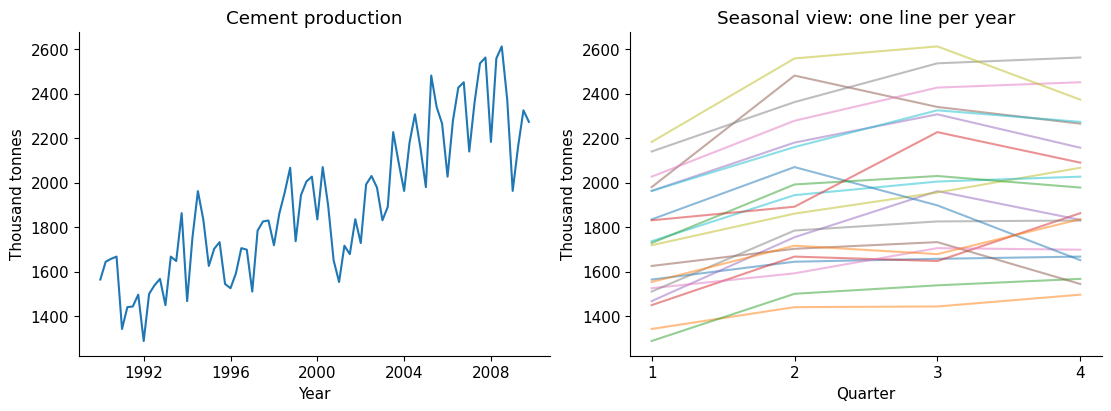

In [3]:
analysis = cement
fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].plot(analysis.index, analysis)
axes[0].set(title="Cement production", xlabel="Year", ylabel="Thousand tonnes")
# Group observations by calendar year to draw one seasonal line per year.
for year, values in analysis.groupby(analysis.index.year):
    axes[1].plot(values.index.quarter, values.to_numpy(), alpha=0.5)
axes[1].set(title="Seasonal view: one line per year", xlabel="Quarter",
            ylabel="Thousand tonnes", xticks=[1, 2, 3, 4])
plt.show()
plt.close(fig)

**Manager’s comment:** Describe the main temporal patterns. Which observations support the claim that this series will be useful for forecasting?

> Cement production remained very steady between 1990 and 1995, before growing to almost 2,400 thousand tons in 2007. The seasonal plot shows repeated seasonality as quarter 1 was the lowest quarter for 16 out of the 18 years. While these trends are useful for forecasting, shifting growth rates and unanticipated decreases can lead to inaccuracies.

### Components / Recent Activity

Using the quarterly cycle, the decomposition separates the underlying level, recurring seasonality, and residual variation.

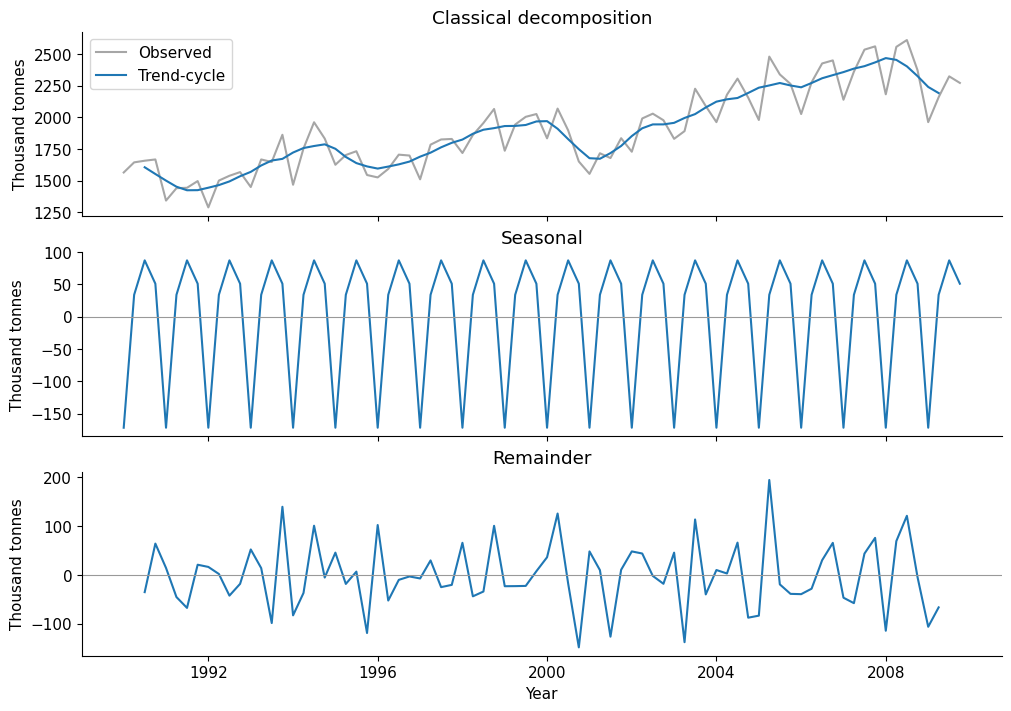

,Quarter effect
quarter,
1,-171.889803
2,33.794408
3,87.103618
4,50.991776


In [4]:
decomposition = seasonal_decompose(analysis, model="additive", period=4)
show_components(analysis, decomposition, "Classical decomposition")

# Direct calculation to check the library's centered trend and seasonal effects.
# These weights center a four-quarter moving average on an observation.
# A complete window needs two observations on either side of its date.
manual_trend = pd.Series(
    np.convolve(analysis.to_numpy(), np.array([1, 2, 2, 2, 1]) / 8, mode="valid"),
    index=analysis.index[2:-2],
)
detrended = analysis.loc[manual_trend.index] - manual_trend
# Average the detrended values for each calendar quarter.
quarter_effects = detrended.groupby(detrended.index.quarter).mean()
# Center the four effects so their mean is zero.
quarter_effects -= quarter_effects.mean()
np.testing.assert_allclose(manual_trend, decomposition.trend.dropna())
display(quarter_effects.rename("Quarter effect").to_frame())

The seasonal pattern represents the same percentage reduction each first quarter, regardless of the production level.

Seasonally adjusted production confirms a substantial decline between late 2006 and early 2007. The downturn is therefore more than the usual first-quarter effect.

In [5]:
adjusted = analysis - decomposition.trend
recent = pd.DataFrame({"Observed": analysis, "Seasonally adjusted": adjusted}).loc[
    "2006-10-01":"2007-04-01"
]
display(recent.round(2))
display(recent.diff().iloc[1:].round(2))

,Observed,Seasonally adjusted
quarter,,
2006-10-01,2451.0,116.50
2007-01-01,2140.0,-218.62
2007-04-01,2362.0,-24.12


,Observed,Seasonally adjusted
quarter,,
2007-01-01,-311.0,-335.12
2007-04-01,222.0,194.50


**Manager’s comment:** Describe the classical decomposition used here and cross-check it with STL using `period=4`, `seasonal=7`, and `robust=True`. Clarify the units of the seasonal effects: does this model describe a constant amount or a constant percentage? Check that the reported adjustment measures what its label claims. Report the observed change from 2006 Q4 to 2007 Q1 and the seasonally adjusted change under each decomposition. Explain what these quantities answer and whether the conclusion about recent activity holds up under STL.

> I used the classical additive decomposition with a centered 2x4 moving average and checked that the manual trend was in agreement with the library output. I changed the seasonal adjustment to subtract the seasonal component instead of the trend, since the additive seasonal impacts represent constant amounts in thousand tons. The measured decrease between 2006 quarter 4 and 2007 quarter 1 amounted to −311 thousand tons, while the corrected adjustments amounted to −105.27 for the classical decomposition and +7.13 for the robust STL. The adjusted changes strip out predicted seasonality and neither suggests any big underlying loss, with the typical decline being around one standard deviation (110 thousand tons) and 13 other adjusted changes being more negative.

### Changes / Dependence

The annual changes look less seasonal than the quarterly changes. The recurring pattern has largely been dealt with.

,Production,Quarterly change,Annual change
quarter,,,
2007-01-01,2140.0,-311.0,-311.0
2007-04-01,2362.0,222.0,222.0
2007-07-01,2536.0,174.0,174.0
2007-10-01,2562.0,26.0,26.0


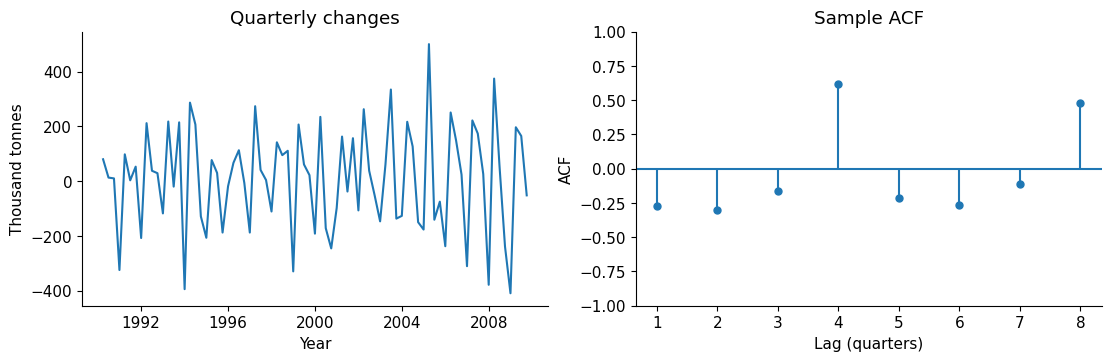

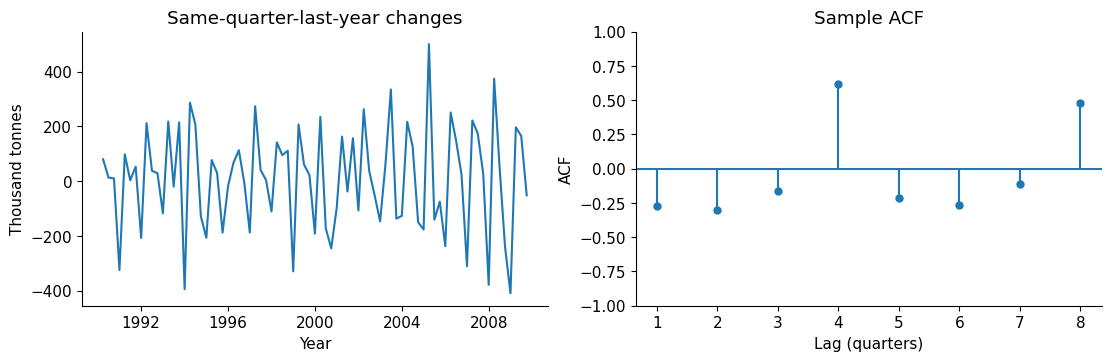

In [6]:
quarter_change = analysis.diff().dropna()
annual_change = analysis.diff().dropna()
display(pd.DataFrame({"Production": analysis, "Quarterly change": quarter_change,
                      "Annual change": annual_change}).loc["2007"].round(2))

# use company helper functions to plot dependence...
show_dependence(quarter_change, "Quarterly changes")
show_dependence(annual_change, "Same-quarter-last-year changes")

**Manager’s comment:** Check that the ordinary and same-quarter-last-year differences answer the different questions their labels imply. Report both changes ending in 2007 Q1, explain what each measures, and verify the annual change against the observations being compared. Assess the annual changes using the time plot, ACF, and a joint statistical test of autocorrelations at lags 1–8. State the tested series, null, test statistic, and p-value. Interpret the result alongside the ACF and explain what the evidence establishes and its limits. Does your test result establish whether the annual-change series is stationary, or whether further differencing is needed? Explain.

> I changed annual changes to diff(4) but kept diff(1) for quarterly modifications. Q1 2007 saw a quarterly change of −311 thousand tons (2,140 − 2,451) and an annual change of +113 (2,140 − 2,027 in Q1 2006). The annual-change figure reveals 47 positive and 21 negative changes among 68 observations, averaging around +45 thousand tons. The quarterly changes held seasonal ACF increases at lags 4 (0.57) and 8 (0.43). The annual changes revealed autocorrelations at lags 1 (0.54), 2 (0.36) and 8 (−0.26), outside the estimated ±0.24 limits. The Ljung–Box test on 68 yearly changes rejected the null hypothesis of a zero autocorrelation across lags 1–8 (Q = 45.53, p = 2.92 × 10⁻⁷). Dependence remains. Nonstationarity is not demonstrated. Additional differencing is not justified.

### Model Attempt

First a straight line, then a line through the decomposed trend with the quarterly effects added back. Both use the same time coordinate.

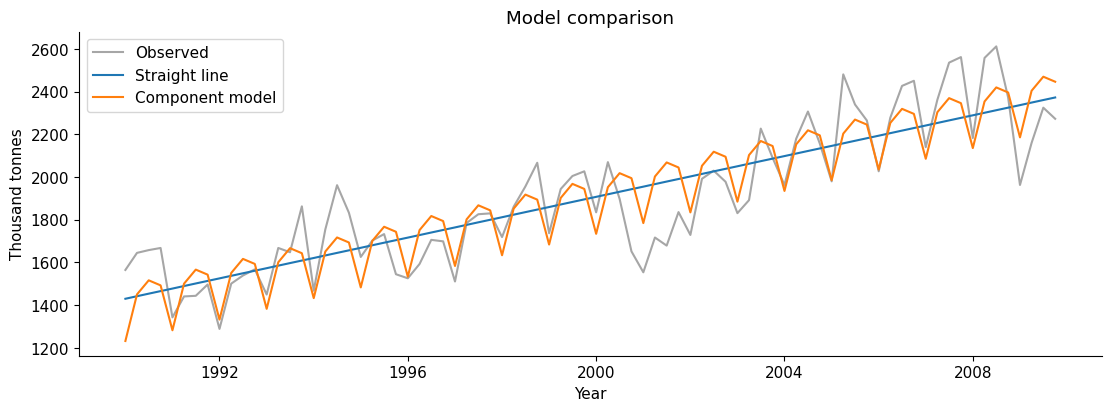

In [7]:
# Number quarters consecutively to give both regressions the same time coordinate.
time = pd.Series(np.arange(len(cement), dtype=float), index=cement.index, name="Quarter number")
# to_frame() supplies the two-dimensional input expected by sklearn.
X = time.loc[analysis.index].to_frame()
baseline = LinearRegression().fit(X, analysis)
# Omit dates where the centered decomposition has no trend estimate.
valid = decomposition.trend.notna()
trend_model = LinearRegression().fit(X.loc[valid], decomposition.trend.loc[valid])
baseline_values = pd.Series(baseline.predict(X), index=analysis.index)
trend_values = pd.Series(trend_model.predict(X), index=analysis.index)
# Look up the seasonal effect for each date by its calendar quarter.
seasonal_values = pd.Series(
    quarter_effects.reindex(analysis.index.quarter).to_numpy(), index=analysis.index
)
component_values = trend_values + seasonal_values

fig, ax = plt.subplots(figsize=(11, 4), layout="constrained")
ax.plot(analysis.index, analysis, color="0.65", label="Observed")
ax.plot(baseline_values.index, baseline_values, label="Straight line")
ax.plot(component_values.index, component_values, label="Component model")
ax.set(title="Model comparison", xlabel="Year", ylabel="Thousand tonnes")
ax.legend()
plt.show()
plt.close(fig)

**Manager’s comment:** Which observations were used to fit these models? Generate time-only regression and classical-component forecasts for the same eight withheld quarters of 2008–2009, using only information available through 2007 Q4. Compare MAE and RMSE, show actuals and forecasts together, and examine the direction or timing of errors as well as the averages. What assumptions about the future trend and seasonal pattern are built into the component forecast? Use your results to discuss where those assumptions may be questionable.

> The inherited analysis used all 80 observations through 2009 Q4, including the assessment period. To compensate for this, I trained through 2007 Q4 (72 observations for the time only regression and 68 for the component trend regression) and then forecasted the eight withheld quarters of 2008–2009. For the component model, MAE improved from 180.22 to 149.95 (16.8%), and RMSE from 213.51 to 170.71 (20.0%). The figure of forecast comparison indicates underprediction for much of 2008 and overprediction for all of 2009. Thus, average errors hide significant time disparities. However, its assumptions of a linear trend increasing by around 12.2 thousand tons every quarter and fixed additive seasonality may not hold when production patterns alter.

### Draft Recommendation

The analysis provides a robust, validated basis for the briefing. The component model follows the quarterly movements much better than the straight line, so it is the recommended forecasting approach. Seasonal effects explain the recurring variation, and the remaining changes show that the late-2006 decline was genuine. The model is ready to use for planning.

**Manager’s comment:** Correct unsupported claims in the inherited recommendation. Explain how decomposing or reconstructing observed production differs from demonstrating forecast accuracy, using evidence from your completed analysis. Then summarize the most important findings about recent activity and forecasting, give a recommendation supported by those findings and their limitations, and identify the next evidence needed before relying on the forecasts for planning. Your response is the completed briefing; refer to the results above rather than repeat the full analysis.

> The acquired claims of a validated model, better historical match, a true major downturn, and planning preparation were overstated. By definition, historical decomposition means reconstructing data (R = Y − T − S), which means that if you accurately rebuild you have not established forecast accuracy. Neither classical nor STL adjustments show indications of a considerable underlying drop between 2006 Q4 and 2007 Q1. The revised holdout comparison favors the component model, MAE=149.95, RMSE=170.71, but it underestimated much of 2008 and overestimated every quarter of 2009. I recommend the classical component model as a basic forecasting strategy, but not yet a completely validated planning tool. Its MAE is approximately 6.5% of average holdout production and the improvement is based on only eight quarters, limiting the generalization . I would do rolling-origin validation, compare to a seasonal naive benchmark, test for based on percentage seasonality, and build prediction intervals to check accuracy prior to operational implementation.

## Check and Submit

Submit one completed `.ipynb` containing the revised analysis, code, results, figures, responses to the manager explaining and verifying your changes, the completed briefing in Draft Recommendation, and assistance disclosure. You may reorganize the notebook; variable names and figure layouts need not match any reference. Preserve useful context, but do not leave unsupported inherited claims presented as your final conclusions. No separate CSV, report, or screenshot is required.

Restart the runtime and run the notebook in order. Retain outputs and check that your explanations agree with them. Download the completed `.ipynb` for submission.

| Evaluation | Points |
| --- | ---: |
| Temporal patterns and decomposition interpretation | 1.0 |
| Seasonal adjustment, STL cross-check, and interpretation of changes | 2.5 |
| Joint dependence check and interpretation | 1.5 |
| Valid forecast comparison, error interpretation, and recommendation | 3.5 |
| Explanation and verification of consequential revisions | 1.0 |
| Reproducibility and assistance disclosure | 0.5 |
| **Total** | **10.0** |

**Assistance disclosure:** Identify material assistance, including AI use, and how you checked it, or write `None`.

> I used paraphrasing tool to reconstruct my sentences and responses.

**Time Report (Required, Ungraded):** Approximately how much active time did you spend on this assignment, and which part required the most effort? Include relevant course-material review and notebook debugging; exclude separate study of general Python fundamentals.

> 60 minutes
